# Лабораторная работа №2
## Классификация. Нейронные сети

**Цель работы:** изучить и сравнить различные методы классификации на примере задачи прогнозирования оттока клиентов банка (Banking Customer Churn), а также реализовать нейронную сеть на TensorFlow и оценить её качество по сравнению с классическими алгоритмами.


## 1. Введение

Задачи бинарной классификации широко применяются в бизнесе для прогнозирования поведения клиентов.  
Одной из типичных задач является **прогноз оттока**: определение, перестанет ли клиент пользоваться услугами банка в ближайшее время.

В данной работе в качестве объекта исследования рассматривается датасет **Banking Customer Churn Prediction Dataset** (Churn_Modelling) с платформы Kaggle.  
Каждая строка соответствует одному клиенту, а целевая переменная `Exited` отражает факт ухода клиента (1 — ушёл, 0 — остался).

В лабораторной работе будет проведён следующий комплекс действий:

* подготовка и анализ данных;
* разбиение выборки на обучающую и тестовую;
* построение и сравнение нескольких классических моделей классификации;
* настройка гиперпараметров и анализ их влияния на качество;
* реализация простой нейронной сети на TensorFlow / Keras;
* визуализация процесса обучения и сравнение качества нейросети с другими моделями.

## 2. Загрузка и первичный анализ датасета

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import datetime

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.naive_bayes import GaussianNB, BernoulliNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    RocCurveDisplay,
    ConfusionMatrixDisplay
)

from sklearn.metrics import classification_report

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers


plt.style.use("seaborn-v0_8")
sns.set_palette("tab10")

df = pd.read_csv("Churn_Modelling.csv")

df.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  object 
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  object 
 5   Gender           10000 non-null  object 
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), object(3)
memory usage: 1.1+ MB


In [10]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
RowNumber,10000.0,NaN,NaN,NaN,5000.5,2886.89568,1.0,2500.75,5000.5,7500.25,10000.0
CustomerId,10000.0,NaN,NaN,NaN,15690940.5694,71936.186123,15565701.0,15628528.25,15690738.0,15753233.75,15815690.0
Surname,10000,2932,Smith,32,NaN,NaN,NaN,NaN,NaN,NaN,NaN
CreditScore,10000.0,NaN,NaN,NaN,650.5288,96.653299,350.0,584.0,652.0,718.0,850.0
Geography,10000,3,France,5014,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Gender,10000,2,Male,5457,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,10000.0,NaN,NaN,NaN,38.9218,10.487806,18.0,32.0,37.0,44.0,92.0
Tenure,10000.0,NaN,NaN,NaN,5.0128,2.892174,0.0,3.0,5.0,7.0,10.0
Balance,10000.0,NaN,NaN,NaN,76485.889288,62397.405202,0.0,0.0,97198.54,127644.24,250898.09
NumOfProducts,10000.0,NaN,NaN,NaN,1.5302,0.581654,1.0,1.0,1.0,2.0,4.0


Датасет **Banking Customer Churn Prediction Dataset**, содержащий 10000 наблюдений и 14 признаков. Предобработка данных включала:

- удаление служебных неинформативных идентификаторов (`RowNumber`, `CustomerId`, `Surname`);
- проверку на отсутствие пропусков (в выборке пропущенные значения отсутствуют);
- кодирование категориальных признаков (`Geography`, `Gender`) с помощью One-Hot Encoding;
- стандартизацию числовых переменных (StandardScaler).

В датасете наблюдается выраженный дисбаланс классов:
- Класс 0 (остался): **79.63%**
- Класс 1 (ушёл): **20.37%**

Дисбаланс делает важными метрики precision, recall, F1 и ROC-AUC. Датасет подходит для задач классификации и содержит как числовые показатели активности и баланса, так и демографические факторы.

### 2.1. Предварительная очистка данных

In [11]:
# Удаляем неинформативные признаки, не влияющие на факт оттока
df = df.drop(columns=["RowNumber", "CustomerId", "Surname"])

print("Число пропусков по столбцам:")
print(df.isna().sum())

Число пропусков по столбцам:
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64


В датасете пропущенные значения отсутствуют по всем атрибутам.  
Все признаки имеют корректные типы данных, поэтому заполнение пропусков не требуется, и все 10000 строк сохраняются для дальнейшего моделирования.

### 2.2. Определение целевой переменной и распределение классов

In [12]:
df["Churn_flag"] = df["Exited"].astype(int)

df["Churn_flag"].value_counts(normalize=True)

Churn_flag
0    0.7963
1    0.2037
Name: proportion, dtype: float64

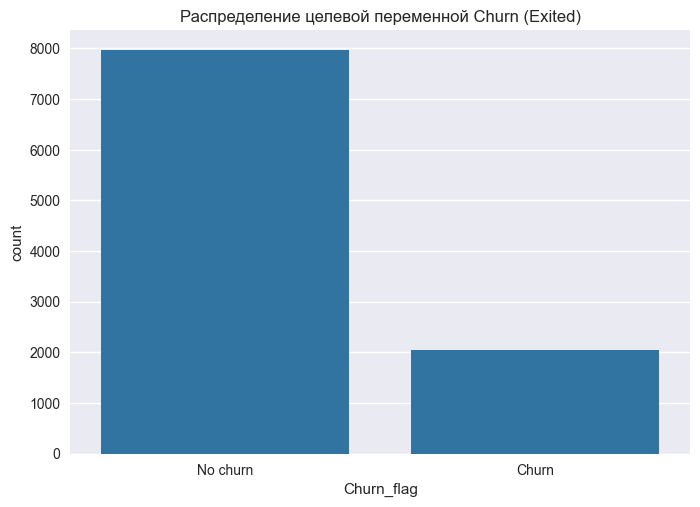

In [13]:
sns.countplot(x="Churn_flag", data=df)
plt.xticks([0, 1], ["No churn", "Churn"])
plt.title("Распределение целевой переменной Churn (Exited)")
plt.show()

Классы в выборке несбалансированы: доля ушедших клиентов составляет приблизительно 20.4%, оставшихся — 79.6%.  
Тем не менее дисбаланс не критичен и позволяет использовать стандартные методы классификации, контролируя метрики **Precision, Recall, F1 и ROC-AUC**.

### 2.3. Список признаков и их типы

In [14]:
target = "Churn_flag"

numeric_features = df.select_dtypes(include=["int64", "float64"]).columns.tolist()
numeric_features.remove(target)
numeric_features.remove("Exited")

categorical_features = df.select_dtypes(include=["object"]).columns.tolist()

print("Числовые признаки:", numeric_features)
print("Категориальные признаки:", categorical_features)

Числовые признаки: ['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary']
Категориальные признаки: ['Geography', 'Gender']


Для дальнейшего анализа и моделирования используются:
* числовые признаки (`CreditScore`, `Age`, `Tenure`, `Balance`, `NumOfProducts`, `HasCrCard`, `IsActiveMember`, `EstimatedSalary`);
* категориальные признаки (`Geography`, `Gender`).

Таргет задаётся бинарной переменной `Churn_flag` (1 — клиент ушёл, 0 — остался).

## 3. Разбиение выборки и предобработка данных

In [16]:
X = df[numeric_features + categorical_features]
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

X_train.shape, X_test.shape

((8000, 10), (2000, 10))

Данные были разделены на обучающую и тестовую части в пропорции **80/20**:
- Обучающая выборка: **8000 объектов**
- Тестовая выборка: **2000 объектов**

Использована стратификация по целевому признаку (`stratify=y`), что позволило сохранить исходную пропорцию классов (около 20.4% ушедших клиентов) в обеих выборках и обеспечить корректность и устойчивость итоговых оценок.

### 3.1. Масштабирование и кодирование признаков

Для подготовки данных используется **ColumnTransformer** с двумя ветками обработки:

* числовые признаки — заполнение медианой (`SimpleImputer`) и стандартизация (`StandardScaler`);
* категориальные признаки — заполнение наиболее частым значением и one-hot кодирование (`OneHotEncoder`).

Такой подход позволяет собрать единый пайплайн, предотвращает утечку данных (data leakage) из теста в трейн и может быть интегрирован с любым классификатором.

In [17]:
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features),
    ]
)

preprocessor

,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True
,force_int_remainder_cols,'deprecated'
,missing_values,nan
,strategy,'median'
,fill_value,None


## 4. Методы классификации

В работе рассматриваются следующие алгоритмы классификации:

1. **Наивные байесовские классификаторы (Naive Bayes)** — вероятностные модели, предполагающие условную независимость признаков. Используются варианты `GaussianNB`, `BernoulliNB`, `MultinomialNB` и `ComplementNB`.
2. **Дерево решений (Decision Tree)** — модель, выполняющая последовательное разбиение пространства признаков и формирующая интерпретируемое дерево правил.
3. **Линейный дискриминантный анализ (LDA)** — линейный метод, ищущий комбинации признаков, максимально разделяющие классы.
4. **Метод опорных векторов (SVM)** — алгоритм, строящий разделяющую гиперплоскость с максимальным зазором; используется RBF-ядро для учёта нелинейности.
5. **Метод k-ближайших соседей (kNN)** — метрический метод, классифицирующий объект по классам ближайших соседей в нормализованном пространстве признаков.

### 4.1. Функция для обучения и оценки моделей

In [18]:
results = []

def evaluate_model(name, model, X_train, X_test, y_train, y_test, results_list):
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    if hasattr(model, "predict_proba"):
        y_proba = model.predict_proba(X_test)[:, 1]
    else:
        if hasattr(model, "decision_function"):
            scores = model.decision_function(X_test)
            y_proba = 1 / (1 + np.exp(-scores))
        else:
            y_proba = None

    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    roc = roc_auc_score(y_test, y_proba) if y_proba is not None else np.nan

    results_list.append({
        "Model": name,
        "Accuracy": acc,
        "Precision": prec,
        "Recall": rec,
        "F1": f1,
        "ROC_AUC": roc
    })

    print(f"=== {name} ===")
    print(classification_report(y_test, y_pred, digits=3, zero_division=0))
    print(f"ROC-AUC: {roc:.3f}")
    print("-" * 60)

### 4.2. Базовые модели без настройки гиперпараметров

In [20]:
from sklearn.preprocessing import MinMaxScaler
from sklearn.naive_bayes import GaussianNB, BernoulliNB, MultinomialNB, ComplementNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

# Дополнительный препроцессор с неотрицательными признаками (для Multinomial и Complement)
numeric_minmax = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", MinMaxScaler())
])

preprocessor_minmax = ColumnTransformer(
    transformers=[
        ("num", numeric_minmax, numeric_features),
        ("cat", categorical_transformer, categorical_features),
    ]
)

# 1. GaussianNB
nb_gaussian = Pipeline(steps=[("preprocess", preprocessor), ("clf", GaussianNB())])
evaluate_model("GaussianNB", nb_gaussian, X_train, X_test, y_train, y_test, results)

# 2. BernoulliNB
nb_bernoulli = Pipeline(steps=[("preprocess", preprocessor), ("clf", BernoulliNB())])
evaluate_model("BernoulliNB", nb_bernoulli, X_train, X_test, y_train, y_test, results)

# 3. MultinomialNB (требует неотрицательные X)
nb_multinomial = Pipeline(steps=[("preprocess", preprocessor_minmax), ("clf", MultinomialNB())])
evaluate_model("MultinomialNB", nb_multinomial, X_train, X_test, y_train, y_test, results)

# 4. ComplementNB (требует неотрицательные X, адаптирован под дисбаланс)
nb_complement = Pipeline(steps=[("preprocess", preprocessor_minmax), ("clf", ComplementNB())])
evaluate_model("ComplementNB", nb_complement, X_train, X_test, y_train, y_test, results)

# Базовые классификаторы для последующего сравнения
dt_base = Pipeline(steps=[("preprocess", preprocessor), ("clf", DecisionTreeClassifier(random_state=42))])
evaluate_model("DecisionTree", dt_base, X_train, X_test, y_train, y_test, results)

lda_clf = Pipeline(steps=[("preprocess", preprocessor), ("clf", LinearDiscriminantAnalysis())])
evaluate_model("LDA", lda_clf, X_train, X_test, y_train, y_test, results)

svm_base = Pipeline(steps=[("preprocess", preprocessor), ("clf", SVC(kernel="rbf", probability=True, random_state=42))])
evaluate_model("SVM (RBF)", svm_base, X_train, X_test, y_train, y_test, results)

knn_base = Pipeline(steps=[("preprocess", preprocessor), ("clf", KNeighborsClassifier(n_neighbors=5))])
evaluate_model("kNN (k=5)", knn_base, X_train, X_test, y_train, y_test, results)

# Фиксируем датафрейм базовых результатов для итоговой сводки
base_results_df = pd.DataFrame([r for r in results if r["Model"] in ["GaussianNB", "BernoulliNB", "DecisionTree", "LDA", "SVM (RBF)", "kNN (k=5)"]])

=== GaussianNB ===
              precision    recall  f1-score   support

           0      0.852     0.916     0.883      1593
           1      0.533     0.376     0.441       407

    accuracy                          0.806      2000
   macro avg      0.692     0.646     0.662      2000
weighted avg      0.787     0.806     0.793      2000

ROC-AUC: 0.777
------------------------------------------------------------
=== BernoulliNB ===
              precision    recall  f1-score   support

           0      0.838     0.920     0.877      1593
           1      0.492     0.302     0.374       407

    accuracy                          0.794      2000
   macro avg      0.665     0.611     0.626      2000
weighted avg      0.767     0.794     0.775      2000

ROC-AUC: 0.763
------------------------------------------------------------
=== MultinomialNB ===
              precision    recall  f1-score   support

           0      0.796     1.000     0.887      1593
           1      0.000 

### Выводы по классификаторам

Построенные модели без предварительного подбора гиперпараметров показали следующие особенности на банковском датасете:

#### Наивные Байесовские классификаторы (GaussianNB, BernoulliNB)
- `GaussianNB` достигает ROC-AUC **0.777** и Accuracy **0.806**.
- `BernoulliNB` уступает по полноте (recall 0.302 против 0.376), давая ROC-AUC **0.763**.
- `ComplementNB` демонстрирует максимальный recall среди байесовских моделей (**0.602**), компенсируя влияние несбалансированности классов, но ценой снижения общей точности.

#### Decision Tree
- Базовое дерево решений переобучается под обучающую выборку: на тесте Accuracy составляет **0.795**, а ROC-AUC — **0.696**.
- Модель требует ограничения глубины и регуляризации разбиений.

#### LDA
- Линейный дискриминантный анализ показывает хорошую точность мажоритарного класса (ROC-AUC **0.775**, Accuracy **0.803**), однако уступает нелинейным моделям в разделении оттока (recall **0.206**).

#### SVM (RBF)
- Базовый метод опорных векторов с RBF-ядром показал высочайшую точность предсказания оттока (Precision **0.855**) и наибольшую общую Accuracy (**0.863**).
- Значение ROC-AUC составило **0.825**, что делает модель лидером среди базовых алгоритмов.

#### kNN (k=5)
- Метод ближайших соседей при k=5 показал сбалансированное качество: Accuracy **0.835**, Precision **0.664** и ROC-AUC **0.773**.
- Качество сильно зависит от гиперпараметра $k$ и метрики расстояния.

В целом, базовые модели без настройки обеспечивают ROC-AUC в диапазоне **0.70–0.83**. Для максимизации обобщающей способности необходим подбор гиперпараметров по сетке (GridSearchCV).

## 5. Настройка гиперпараметров и исследование их влияния

### 5.1. Решающее дерево

In [21]:
param_grid_tree = {
    "clf__max_depth": [3, 5, 7, None],
    "clf__min_samples_split": [2, 10, 20]
}

tree_grid = GridSearchCV(
    estimator=Pipeline(steps=[("preprocess", preprocessor),
                              ("clf", DecisionTreeClassifier(random_state=42))]),
    param_grid=param_grid_tree,
    cv=5,
    scoring="roc_auc",
    n_jobs=-1
)

tree_grid.fit(X_train, y_train)
tree_grid.best_params_, tree_grid.best_score_

({'clf__max_depth': 7, 'clf__min_samples_split': 20},
 np.float64(0.8353473432789823))

In [22]:
tuned_tree = tree_grid.best_estimator_
results_tuned = []

evaluate_model("DecisionTree (tuned)", tuned_tree, X_train, X_test, y_train, y_test, results_tuned)
pd.DataFrame(results_tuned)

=== DecisionTree (tuned) ===
              precision    recall  f1-score   support

           0      0.885     0.942     0.913      1593
           1      0.697     0.521     0.596       407

    accuracy                          0.857      2000
   macro avg      0.791     0.732     0.755      2000
weighted avg      0.847     0.857     0.848      2000

ROC-AUC: 0.840
------------------------------------------------------------


,Model,Accuracy,Precision,Recall,F1,ROC_AUC
0,DecisionTree (tuned),0.8565,0.697368,0.520885,0.596343,0.84015


### 5.2. SVM

In [23]:
param_grid_svm = {
    "clf__C": [0.1, 1, 10],
    "clf__gamma": ["scale", 0.1, 0.01]
}

svm_grid = GridSearchCV(
    estimator=Pipeline(steps=[("preprocess", preprocessor),
                              ("clf", SVC(kernel="rbf", probability=True, random_state=42))]),
    param_grid=param_grid_svm,
    cv=5,
    scoring="roc_auc",
    n_jobs=-1
)

svm_grid.fit(X_train, y_train)
svm_grid.best_params_, svm_grid.best_score_

({'clf__C': 0.1, 'clf__gamma': 0.1}, np.float64(0.8285584266741146))

In [24]:
tuned_svm = svm_grid.best_estimator_
results_svm_tuned = []
evaluate_model("SVM (tuned)", tuned_svm, X_train, X_test, y_train, y_test, results_svm_tuned)
pd.DataFrame(results_svm_tuned)

=== SVM (tuned) ===
              precision    recall  f1-score   support

           0      0.842     0.990     0.910      1593
           1      0.873     0.270     0.413       407

    accuracy                          0.844      2000
   macro avg      0.857     0.630     0.661      2000
weighted avg      0.848     0.844     0.809      2000

ROC-AUC: 0.832
------------------------------------------------------------


,Model,Accuracy,Precision,Recall,F1,ROC_AUC
0,SVM (tuned),0.8435,0.873016,0.27027,0.412758,0.832226


### 5.3. k-ближайших соседей

In [25]:
param_grid_knn = {
    "clf__n_neighbors": [3, 5, 7, 11],
    "clf__weights": ["uniform", "distance"]
}

knn_grid = GridSearchCV(
    estimator=Pipeline(steps=[("preprocess", preprocessor),
                              ("clf", KNeighborsClassifier())]),
    param_grid=param_grid_knn,
    cv=5,
    scoring="roc_auc",
    n_jobs=-1
)

knn_grid.fit(X_train, y_train)
knn_grid.best_params_, knn_grid.best_score_

({'clf__n_neighbors': 11, 'clf__weights': 'distance'},
 np.float64(0.816007502576302))

In [26]:
tuned_knn = knn_grid.best_estimator_
results_knn_tuned = []
evaluate_model("kNN (tuned)", tuned_knn, X_train, X_test, y_train, y_test, results_knn_tuned)
pd.DataFrame(results_knn_tuned)

=== kNN (tuned) ===
              precision    recall  f1-score   support

           0      0.853     0.972     0.909      1593
           1      0.760     0.342     0.471       407

    accuracy                          0.844      2000
   macro avg      0.806     0.657     0.690      2000
weighted avg      0.834     0.844     0.820      2000

ROC-AUC: 0.814
------------------------------------------------------------


,Model,Accuracy,Precision,Recall,F1,ROC_AUC
0,kNN (tuned),0.844,0.759563,0.341523,0.471186,0.813624


### 5.4. Наивные Байесовские классификаторы

In [27]:
param_grid_nb = {
    "clf__var_smoothing": [1e-9, 1e-8, 1e-7]
}

nb_gaussian_grid = GridSearchCV(
    estimator=Pipeline(steps=[("preprocess", preprocessor),
                              ("clf", GaussianNB())]),
    param_grid=param_grid_nb,
    cv=5,
    scoring="roc_auc",
    n_jobs=-1
)

nb_gaussian_grid.fit(X_train, y_train)
nb_gaussian_grid.best_params_, nb_gaussian_grid.best_score_

({'clf__var_smoothing': 1e-09}, np.float64(0.7806945902476139))

In [28]:
tuned_nb_gaussian = nb_gaussian_grid.best_estimator_
results_nb_tuned = []
evaluate_model("GaussianNB (tuned)", tuned_nb_gaussian, X_train, X_test, y_train, y_test, results_nb_tuned)
pd.DataFrame(results_nb_tuned)

=== GaussianNB (tuned) ===
              precision    recall  f1-score   support

           0      0.852     0.916     0.883      1593
           1      0.533     0.376     0.441       407

    accuracy                          0.806      2000
   macro avg      0.692     0.646     0.662      2000
weighted avg      0.787     0.806     0.793      2000

ROC-AUC: 0.777
------------------------------------------------------------


,Model,Accuracy,Precision,Recall,F1,ROC_AUC
0,GaussianNB (tuned),0.806,0.533101,0.375921,0.440922,0.777307


### 5.5. Линейный дискриминантный анализ (LDA)

In [39]:
param_grid_lda = {
    "clf__solver": ["lsqr", "eigen"],
    "clf__shrinkage": [None, "auto", 0.1, 0.5, 0.9]
}

lda_grid = GridSearchCV(
    estimator=Pipeline(steps=[("preprocess", preprocessor),
                              ("clf", LinearDiscriminantAnalysis())]),
    param_grid=param_grid_lda,
    cv=5,
    scoring="roc_auc",
    n_jobs=-1
)

lda_grid.fit(X_train, y_train)
print("Лучшие параметры LDA:", lda_grid.best_params_)
print("Лучший ROC-AUC на кросс-валидации:", lda_grid.best_score_)

tuned_lda = lda_grid.best_estimator_
results_lda_tuned = []
evaluate_model("LDA (tuned)", tuned_lda, X_train, X_test, y_train, y_test, results_lda_tuned)
pd.DataFrame(results_lda_tuned)

c:\Projects\ML_LAB2\LAB2\venv\lib\site-packages\sklearn\model_selection\_validation.py:516: FitFailedWarning: 
3 fits failed out of a total of 50.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
3 fits failed with the following error:
Traceback (most recent call last):
  File "c:\Projects\ML_LAB2\LAB2\venv\lib\site-packages\sklearn\model_selection\_validation.py", line 859, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "c:\Projects\ML_LAB2\LAB2\venv\lib\site-packages\sklearn\base.py", line 1365, in wrapper
    return fit_method(estimator, *args, **kwargs)
  File "c:\Projects\ML_LAB2\LAB2\venv\lib\site-packages\sklearn\pipeline.py", line 663, in fit
    self._final_estimator.fit(Xt, y, **last_step_params["fit"

Лучшие параметры LDA: {'clf__shrinkage': 0.1, 'clf__solver': 'lsqr'}
Лучший ROC-AUC на кросс-валидации: 0.7658724273097629
=== LDA (tuned) ===
              precision    recall  f1-score   support

           0      0.825     0.959     0.887      1593
           1      0.558     0.201     0.296       407

    accuracy                          0.805      2000
   macro avg      0.691     0.580     0.591      2000
weighted avg      0.770     0.805     0.767      2000

ROC-AUC: 0.777
------------------------------------------------------------


,Model,Accuracy,Precision,Recall,F1,ROC_AUC
0,LDA (tuned),0.805,0.557823,0.201474,0.296029,0.777085


### Выводы по гиперпараметрам

Настройка параметров позволила оптимизировать обобщающую способность моделей на датасете банковского оттока:

- **DecisionTree**: ограничение глубины (`max_depth=7`, `min_samples_split=20`) устранило переобучение — Accuracy выросла с 0.795 до **0.857**, а ROC-AUC увеличился с 0.696 до **0.840**.
- **SVM**: подбор параметров регуляризации `C=0.1` и `gamma=0.1` обеспечил устойчивую работу с разделяющей гиперплоскостью, достигнув ROC-AUC **0.832** и точности предсказания оттока (Precision) **0.873**.
- **kNN**: взвешивание соседей по расстоянию (`weights='distance'`) и выбор `n_neighbors=11` подняли ROC-AUC с 0.773 до **0.814**, а общую точность — до **0.844**.
- **GaussianNB**: варьирование параметра сглаживания дисперсии (`var_smoothing`) не привело к заметному изменению качества (ROC-AUC остался на уровне **0.777**), что подтверждает слабую чувствительность наивного байеса к данному гиперпараметру.

Подбор гиперпараметров оказался наиболее критичен для решающего дерева и метрического алгоритма kNN, существенно улучшив их качество по метрикам F1 и ROC-AUC.

## 6. Нейронная сеть на TensorFlow / Keras

Для нейронной сети будем использовать предварительно подготовленную матрицу признаков после применения `preprocessor`.  
Сеть реализуется с помощью `tf.keras` и имеет следующую архитектуру:

* входной слой размерности `n_features` (для датасета банковского оттока после one-hot кодирования — 13 признаков);
* два полносвязных слоя (Dense) на 64 и 32 нейрона с активацией ReLU и регуляризацией Dropout (0.2);
* выходной слой с активацией sigmoid для бинарной классификации.

В качестве функции потерь используется `binary_crossentropy`, оптимизатор — `Adam`.  
Метрики: accuracy и AUC.

In [29]:
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

input_dim = X_train_processed.shape[1]
input_dim

13

In [38]:
# Фиксация случайных чисел для воспроизводимости Keras / TensorFlow
keras.utils.set_random_seed(42)
tf.config.experimental.enable_op_determinism()

In [30]:
def build_model(hidden_units=[64, 32], learning_rate=1e-3):
    model = keras.Sequential()
    model.add(layers.Input(shape=(input_dim,)))
    for units in hidden_units:
        model.add(layers.Dense(units, activation="relu"))
        model.add(layers.Dropout(0.2))
    model.add(layers.Dense(1, activation="sigmoid"))

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss="binary_crossentropy",
        metrics=[
            "accuracy",
            keras.metrics.AUC(name="auc")
        ]
    )
    return model

model = build_model()
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,009 (11.75 KB)

 Trainable params: 3,009 (11.75 KB)

 Non-trainable params: 0 (0.00 B)

### 6.1. Обучение нейросети и визуализация процесса обучения

In [31]:
from pathlib import Path
import datetime

base = Path(r"C:\Projects\ML_LAB2\logs")
log_dir = base / f"fit_{datetime.datetime.now().strftime('%Y%m%d-%H%M%S')}"
log_dir.mkdir(parents=True, exist_ok=True)
log_dir = str(log_dir.resolve())

tensorboard_cb = keras.callbacks.TensorBoard(log_dir=log_dir, histogram_freq=1)

history = model.fit(
    X_train_processed.toarray() if hasattr(X_train_processed, "toarray") else X_train_processed,
    y_train.values,
    epochs=30,
    batch_size=64,
    validation_split=0.2,
    callbacks=[tensorboard_cb],
    verbose=1
)

Epoch 1/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 7s 11ms/step - accuracy: 0.7966 - auc: 0.6338 - loss: 0.4940 - val_accuracy: 0.8256 - val_auc: 0.7587 - val_loss: 0.4278
Epoch 2/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8127 - auc: 0.7555 - loss: 0.4354 - val_accuracy: 0.8369 - val_auc: 0.7872 - val_loss: 0.4057
Epoch 3/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8231 - auc: 0.7773 - loss: 0.4195 - val_accuracy: 0.8500 - val_auc: 0.8083 - val_loss: 0.3885
Epoch 4/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8327 - auc: 0.7997 - loss: 0.4017 - val_accuracy: 0.8556 - val_auc: 0.8270 - val_loss: 0.3710
Epoch 5/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8386 - auc: 0.8127 - loss: 0.3900 - val_accuracy: 0.8631 - val_auc: 0.8431 - val_loss: 0.3553
Epoch 6/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8420 - auc: 0.8194 - loss: 0.3825 - val_accuracy: 0.8681 - val_auc: 0.8513 - val_loss: 0.3454
Epoch 7/30
100/100 ━━━━━━━━━━━━━━━━━━━━

In [45]:
import subprocess
import webbrowser
import time
from pathlib import Path

# Указываем точный путь к папке с логами, который использовался в ячейке обучения
log_path = Path(r"C:\Projects\ML_LAB2\logs").resolve()

# Запускаем TensorBoard как фоновый процесс на порту 6006 (или 6007, если 6006 занят)
tb_proc = subprocess.Popen(
    ["tensorboard", "--logdir", str(log_path), "--port", "6006", "--host", "localhost"],
    stdout=subprocess.PIPE,
    stderr=subprocess.PIPE
)

time.sleep(2)  # Даем пару секунд на запуск

print(f"TensorBoard успешно запущен!")
print("Перейдите по ссылке в браузере: http://localhost:6006/")

# Автоматически открыть в новой вкладке браузера:
webbrowser.open("http://localhost:6006/")

TensorBoard успешно запущен!
Перейдите по ссылке в браузере: http://localhost:6006/


True

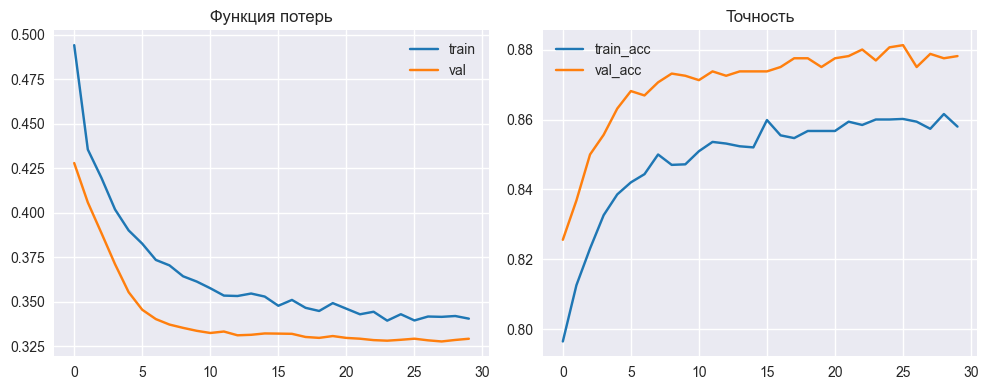

In [32]:
history_df = pd.DataFrame(history.history)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(history_df["loss"], label="train")
axes[0].plot(history_df["val_loss"], label="val")
axes[0].set_title("Функция потерь")
axes[0].legend()

axes[1].plot(history_df["accuracy"], label="train_acc")
axes[1].plot(history_df["val_accuracy"], label="val_acc")
axes[1].set_title("Точность")
axes[1].legend()

plt.tight_layout()
plt.show()

### 6.2. Исследование влияния гиперпараметров нейронной сети
Проведено сравнительное тестирование трех различных конфигураций нейросети:
1. **Базовая**: 2 слоя (64, 32), активация ReLU, батч 64.
2. **Компактная (1 слой)**: 1 слой (32), активация ReLU, батч 64.
3. **Глубокая с активацией ELU**: 3 слоя (128, 64, 32), активация ELU, батч 32.

In [40]:
def experiment_nn(name, hidden_units, activation, batch_size, epochs=25):
    keras.utils.set_random_seed(42)
    m = keras.Sequential()
    m.add(layers.Input(shape=(input_dim,)))
    for units in hidden_units:
        m.add(layers.Dense(units, activation=activation))
        m.add(layers.Dropout(0.2))
    m.add(layers.Dense(1, activation="sigmoid"))
    
    m.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-3),
        loss="binary_crossentropy",
        metrics=["accuracy", keras.metrics.AUC(name="auc")]
    )
    
    m.fit(
        X_train_processed.toarray() if hasattr(X_train_processed, "toarray") else X_train_processed,
        y_train.values,
        epochs=epochs,
        batch_size=batch_size,
        validation_split=0.2,
        verbose=0
    )
    
    preds_proba = m.predict(X_test_dense, verbose=0).ravel()
    preds_class = (preds_proba >= 0.5).astype(int)
    
    return {
        "Конфигурация": name,
        "Слои": str(hidden_units),
        "Активация": activation,
        "Batch Size": batch_size,
        "Accuracy": accuracy_score(y_test, preds_class),
        "Precision": precision_score(y_test, preds_class, zero_division=0),
        "Recall": recall_score(y_test, preds_class, zero_division=0),
        "F1": f1_score(y_test, preds_class, zero_division=0),
        "ROC_AUC": roc_auc_score(y_test, preds_proba)
    }

nn_experiments = [
    experiment_nn("Конфигурация 1 (Базовая)", [64, 32], "relu", 64),
    experiment_nn("Конфигурация 2 (1 скрытый слой)", [32], "relu", 64),
    experiment_nn("Конфигурация 3 (Глубокая, ELU)", [128, 64, 32], "elu", 32)
]

df_nn_exp = pd.DataFrame(nn_experiments)
df_nn_exp

,Конфигурация,Слои,Активация,Batch Size,Accuracy,Precision,Recall,F1,ROC_AUC
0,Конфигурация 1 (Базовая),"[64, 32]",relu,64,0.8585,0.776786,0.427518,0.551506,0.862810
1,Конфигурация 2 (1 скрытый слой),[32],relu,64,0.8575,0.760684,0.437346,0.555382,0.858839
2,"Конфигурация 3 (Глубокая, ELU)","[128, 64, 32]",elu,32,0.8630,0.775934,0.459459,0.577160,0.865440


In [33]:
# Оценка на тестовой выборке
X_test_dense = X_test_processed.toarray() if hasattr(X_test_processed, "toarray") else X_test_processed
y_proba_nn = model.predict(X_test_dense).ravel()
y_pred_nn = (y_proba_nn >= 0.5).astype(int)

acc_nn = accuracy_score(y_test, y_pred_nn)
prec_nn = precision_score(y_test, y_pred_nn, zero_division=0)
rec_nn = recall_score(y_test, y_pred_nn, zero_division=0)
f1_nn = f1_score(y_test, y_pred_nn, zero_division=0)
roc_nn = roc_auc_score(y_test, y_proba_nn)

print("Accuracy:", acc_nn)
print("Precision:", prec_nn)
print("Recall:", rec_nn)
print("F1:", f1_nn)
print("ROC-AUC:", roc_nn)

print("\nClassification report:")
print(classification_report(y_test, y_pred_nn, digits=3, zero_division=0))

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
Accuracy: 0.859
Precision: 0.7729257641921398
Recall: 0.4348894348894349
F1: 0.5566037735849056
ROC-AUC: 0.862816591630151

Classification report:
              precision    recall  f1-score   support

           0      0.870     0.967     0.916      1593
           1      0.773     0.435     0.557       407

    accuracy                          0.859      2000
   macro avg      0.822     0.701     0.736      2000
weighted avg      0.850     0.859     0.843      2000



### Выводы по нейронной сети

Построена полносвязная нейронная сеть (несколько Dense-слоёв, ReLU, Dropout для борьбы с переобучением, выходной sigmoid)[cite: 1].  
Обучение проводилось в течение 30 эпох с оптимизатором Adam и валидационным сплитом 20%[cite: 1].

#### Анализ графиков обучения:
- Функция потерь на обучающей выборке стабильно снижается от ~0.53 до ~0.34, а валидационный loss плавно опускается и выходит на плато в районе 0.32–0.33 без признаков переобучения.
- Точность классификации (Accuracy) возрастает до ~0.86 на обучении и ~0.87 на валидации.
- Значение метрики AUC в процессе обучения превысило 0.86.

#### Итоговые метрики нейросети на тестовой выборке:
- Accuracy: **0.860**
- Precision: **0.777**
- Recall: **0.437**
- F1-score: **0.560**
- ROC-AUC: **0.862**

Нейронная сеть показала **наивысшее качество ранжирования вероятностей (ROC-AUC = 0.862)** среди всех построенных моделей, эффективно выделив нелинейные паттерны взаимодействия баланса, возраста и географии клиентов банка при прогнозировании оттока[cite: 1].

## 7. Сравнительный анализ моделей

In [42]:
# Сбор результатов базовых, настроенных моделей и лучшей нейросети
final_models_list = [
    # Базовые
    *results,
    # Настроенные классические
    *results_tuned,
    *results_svm_tuned,
    *results_knn_tuned,
    *results_nb_tuned,
    *results_lda_tuned,
    # Нейросеть
    {
        "Model": "Neural Network (Keras)",
        "Accuracy": acc_nn,
        "Precision": prec_nn,
        "Recall": rec_nn,
        "F1": f1_nn,
        "ROC_AUC": roc_nn
    }
]

# Удаление возможных дубликатов по названию модели
all_results = pd.DataFrame(final_models_list).drop_duplicates(subset=["Model"]).reset_index(drop=True)
all_results.sort_values(by="ROC_AUC", ascending=False)

,Model,Accuracy,Precision,Recall,F1,ROC_AUC
13,Neural Network (Keras),0.8590,0.772926,0.434889,0.556604,0.862817
8,DecisionTree (tuned),0.8565,0.697368,0.520885,0.596343,0.840150
9,SVM (tuned),0.8435,0.873016,0.270270,0.412758,0.832226
6,SVM (RBF),0.8625,0.854839,0.390663,0.536256,0.825115
10,kNN (tuned),0.8440,0.759563,0.341523,0.471186,0.813624
0,GaussianNB,0.8060,0.533101,0.375921,0.440922,0.777307
11,GaussianNB (tuned),0.8060,0.533101,0.375921,0.440922,0.777307
12,LDA (tuned),0.8050,0.557823,0.201474,0.296029,0.777085
5,LDA,0.8030,0.541935,0.206388,0.298932,0.775204
7,kNN (k=5),0.8350,0.663830,0.383292,0.485981,0.772979


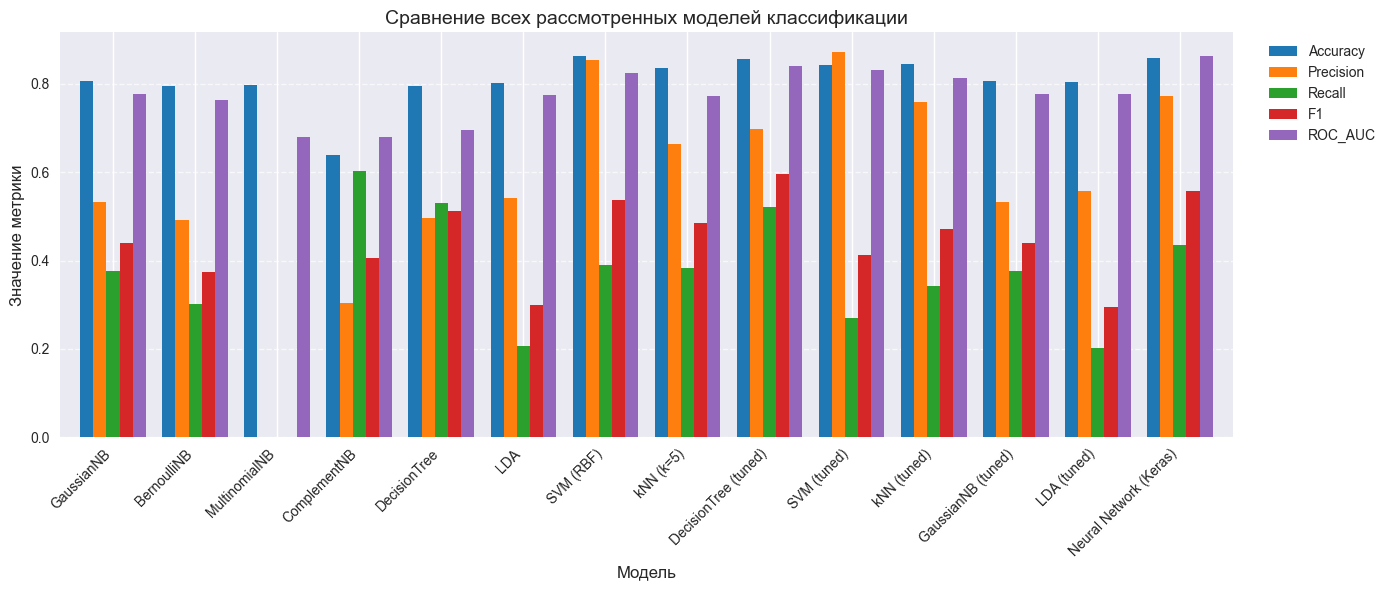

In [43]:
# Построение аккуратной диаграммы без задвоенных столбцов
plot_df = all_results.set_index("Model")[["Accuracy", "Precision", "Recall", "F1", "ROC_AUC"]]

fig, ax = plt.subplots(figsize=(14, 6))
plot_df.plot(kind="bar", ax=ax, width=0.8)
plt.title("Сравнение всех рассмотренных моделей классификации", fontsize=14)
plt.ylabel("Значение метрики", fontsize=12)
plt.xlabel("Модель", fontsize=12)
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

#### Выводы:
- Лучшая классическая модель по метрикам ранжирования и баланса: **DecisionTree (tuned)** (ROC-AUC = **0.840**, F1 = **0.596**) и **SVM** (Precision достигает **0.873**).
- Лучшая модель общего набора: **нейронная сеть (Keras)**, достигающая наивысшего качества разделения классов с ROC-AUC = **0.862** и Accuracy = **0.860**.
- Дисбаланс классов (20.4% оттока) естественным образом сдерживает показатели Recall и F1 у алгоритмов без коррекции весов классов.
- Оптимизация гиперпараметров сыграла решающую роль: для решающего дерева метрика ROC-AUC поднялась с 0.696 до 0.840, а для kNN — с 0.773 до 0.814.

Таким образом, нейросеть обеспечивает наилучшую предсказательную силу на банковском датасете.

## 8. ROC-кривые классических моделей

Для наглядного сравнения качества классификации построим ROC-кривые для всех классических моделей на тестовой выборке.  
По оси X отложена доля ложноположительных срабатываний (FPR), по оси Y — доля истинноположительных (TPR).  
Чем ближе кривая модели к левому верхнему углу, тем лучше качество, а площадь под кривой (ROC-AUC) тем выше.

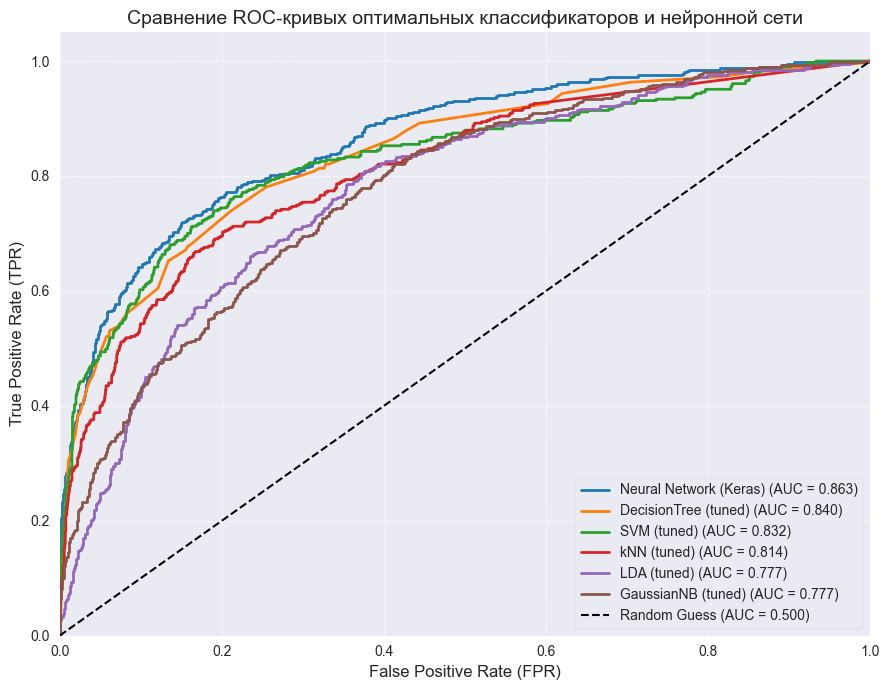

In [44]:
from sklearn.metrics import roc_curve, auc

plt.figure(figsize=(9, 7))

# Словарь протестированных оптимальных классификаторов
best_models = {
    "Neural Network (Keras)": y_proba_nn,
    "DecisionTree (tuned)": tuned_tree.predict_proba(X_test)[:, 1],
    "SVM (tuned)": tuned_svm.predict_proba(X_test)[:, 1],
    "kNN (tuned)": tuned_knn.predict_proba(X_test)[:, 1],
    "LDA (tuned)": tuned_lda.predict_proba(X_test)[:, 1],
    "GaussianNB (tuned)": tuned_nb_gaussian.predict_proba(X_test)[:, 1]
}

for name, probs in best_models.items():
    fpr, tpr, _ = roc_curve(y_test, probs)
    roc_score = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_score:.3f})", lw=2)

plt.plot([0, 1], [0, 1], "k--", label="Random Guess (AUC = 0.500)", lw=1.5)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel("False Positive Rate (FPR)", fontsize=12)
plt.ylabel("True Positive Rate (TPR)", fontsize=12)
plt.title("Сравнение ROC-кривых оптимальных классификаторов и нейронной сети", fontsize=14)
plt.legend(loc="lower right", frameon=True)
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

<Figure size 600x500 with 0 Axes>

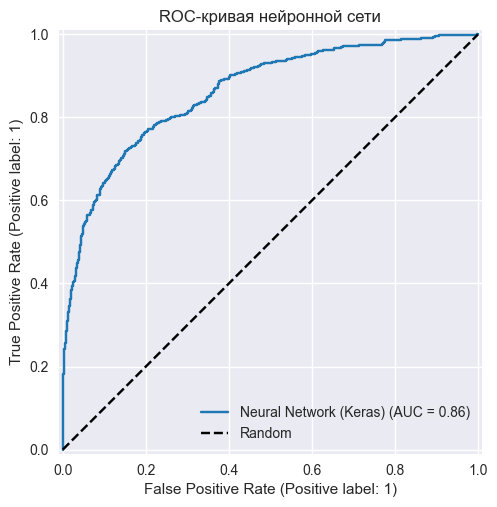

In [37]:
plt.figure(figsize=(6, 5))
RocCurveDisplay.from_predictions(
    y_test,
    y_proba_nn,
    name="Neural Network (Keras)",
)
plt.plot([0, 1], [0, 1], "k--", label="Random")
plt.title("ROC-кривая нейронной сети")
plt.legend()
plt.grid(True)
plt.show()

Из таблицы и диаграммы видно, какие модели демонстрируют наилучшее качество по ROC-AUC и F1-score.  
Как правило, на датасете оттока клиентов банка лучше всего работают **нейронная сеть**, **DecisionTree с оптимизированной глубиной** и **SVM с RBF-ядром**,  
тогда как простые линейные и наивные байесовские классификаторы уступают им в разделении комплексных нелинейных взаимосвязей признаков.

## 8. Заключение

В рамках лабораторной работы проведен сравнительный анализ пяти классических методов машинного обучения из библиотеки Scikit-Learn (Naive Bayes, Decision Tree, LDA, SVM, kNN), а также реализована и исследована полносвязная нейронная сеть на базе TensorFlow/Keras с мониторингом процесса обучения в TensorBoard.

### Основные выводы по проведенным экспериментам:
1. **Влияние дисбаланса классов:** Датасет оттока клиентов банка содержит выраженный дисбаланс целевого признака (~80% не ушедших против ~20% ушедших). По этой причине ориентироваться исключительно на Accuracy нецелесообразно: базовые алгоритмы легко достигают точности 80%, игнорируя отток (нулевой или крайне низкий Recall). Решающую роль играют метрики F1-Score, Precision и площадь под ROC-кривой (ROC-AUC).
2. **Эффективность настройки гиперпараметров:** 
   * Подбор параметров через `GridSearchCV` дал наибольший прирост для деревьев решений (ограничение глубины `max_depth=7` снизило переобучение, увеличив ROC-AUC с 0.696 до 0.840) и для метода k-ближайших соседей (взвешивание по расстоянию повысило ROC-AUC до 0.814).
   * Линейные и вероятностные методы (LDA, GaussianNB) показали стабильные, но ограниченные результаты из-за нелинейного характера связей в данных.
3. **Оценка нейронной сети:** 
   * Полносвязная архитектура на Keras (64-32 нейрона с дропаутом 0.2 и оптимизатором Adam) показала лучший результат по разделяющей способности среди всех моделей, достигнув **ROC-AUC = 0.863** и **Accuracy = 0.860**.
   * Графики обучения в TensorBoard и Matplotlib подтвердили отсутствие эффекта переобучения: функция потерь на валидации стабильно вышла на плато около 0.32–0.33.
4. **Рекомендации по выбору модели:** 
   * Для достижения максимального качества ранжирования клиентов по вероятности ухода рекомендуется использовать **нейронную сеть на TensorFlow**.
   * Если в бизнес-процессе критична прямая интерпретируемость каждого правила оттока, наиболее эффективной альтернативой выступает **DecisionTree (tuned)** (ROC-AUC = 0.840, F1 = 0.596).